# LOGISMART — Evidencias de modelado y evaluación (H4–H5)

Este notebook **documenta e interpreta los resultados** producidos por los módulos de `src/`; no entrena modelos ni recalcula SHAP. Su objetivo es servir como evidencia académica del proceso CRISP-DM.

**Fuente de los resultados:** `output/resultados/*.json` y `output/graficos/*.png`, generados por los comandos `python main.py --proceso entrenar`, `evaluar` y `explicar`.

**Alcance:** todos los registros son sintéticos. Las métricas y explicaciones describen el comportamiento del modelo en la simulación, no su rendimiento operativo real. Las cifras comentadas corresponden a la ejecución completa documentada; si se regenera el dataset, se cambia el modelo o se modifica la semilla, deberán actualizarse las interpretaciones.


In [9]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

BASE = Path.cwd()
if BASE.name == "notebooks":
    BASE = BASE.parent
ruta = BASE / "output" / "resultados" / "resultados_modelado.json"
if not ruta.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso entrenar")
resultados = json.loads(ruta.read_text(encoding="utf-8"))
print("Modelo elegido:", resultados["modelo_elegido"])
print("Modo rápido:", resultados["modo_rapido"])
print("Períodos:", resultados["periodos"])
print("Filas usadas:", resultados["filas_utilizadas"])

Modelo elegido: XGBoost
Modo rápido: False
Períodos: {'train': '2025-08 a 2026-06', 'validacion': '2026-07', 'test': '2026-08 a 2026-09'}
Filas usadas: {'train': 825299, 'validacion': 74766, 'test': 149935}


## Comparación de modelos en validación

Se utilizó una **división temporal**: entrenamiento (agosto de 2025 a junio de 2026), validación (julio de 2026) y prueba final (agosto–septiembre de 2026). Las transformaciones que aprenden de los datos, incluida la imputación, se ajustan solamente con entrenamiento.

Se compararon **Random Forest** y **XGBoost** sobre julio de 2026. XGBoost obtuvo ROC-AUC **0.7037** y PR-AUC **0.2898**, frente a **0.6984** y **0.2848** de Random Forest, respectivamente. Por ello, se seleccionó XGBoost según el criterio implementado (ROC-AUC y PR-AUC como desempate).

Las métricas de clasificación de esta tabla usan un umbral fijo de **0.5**, solo como referencia. Con ese umbral, XGBoost recupera aproximadamente **0.98 %** de los retrasos de validación; por tanto, se requiere analizar un umbral alternativo para fines preventivos. **El conjunto de test no intervino en la selección del modelo ni del umbral.**


In [10]:
tabla = pd.DataFrame(resultados["resultados_validacion_umbral_0_5"]).T
display(tabla.drop(columns=["matriz_confusion"]).round(4))

,roc_auc,pr_auc,precision,recall,f1,tasa_retraso_real,tasa_alertas,umbral
Random Forest,0.698365,0.28482,1.0,0.000097,0.000194,0.13767,0.000013,0.5
XGBoost,0.703692,0.289849,0.647436,0.009812,0.019332,0.13767,0.002087,0.5


## Evaluación final en test

El modelo seleccionado se evaluó con los datos de **agosto y septiembre de 2026**, manteniendo el umbral definido en validación (**0.15**).

**Resultados obtenidos:** ROC-AUC **0.7074**; PR-AUC **0.3044**; precisión **34.56 %**; recall **30.95 %**; F1 **0.3265**. El modelo genera alertas para el **13.02 %** de las operaciones de prueba.

Según la matriz de confusión, de **21.795** retrasos reales se detectaron **6.746** y quedaron sin alerta **15.049**; además hubo **12.776** falsas alarmas. Esto evidencia una capacidad de discriminación útil para priorización, pero una sensibilidad limitada si la meta es advertir la mayoría de los retrasos.

La tasa de retraso observada en test fue **14.54 %**, mientras que la precisión de las alertas fue **34.56 %**, aproximadamente **2.38 veces** la tasa base. Esta concentración no demuestra que emitir una alerta evite un retraso.


In [11]:
r = resultados["resultado_test"]
display(pd.Series({k: v for k, v in r.items() if k != "matriz_confusion"}, name="Test").to_frame())
print("Matriz de confusión [TN, FP; FN, TP]:")
print(pd.DataFrame(r["matriz_confusion"], index=["Real 0", "Real 1"], columns=["Pred 0", "Pred 1"]))

,Test
roc_auc,0.707352
pr_auc,0.304437
precision,0.345559
recall,0.309521
f1,0.326548
tasa_retraso_real,0.145363
tasa_alertas,0.130203
umbral,0.150000


Matriz de confusión [TN, FP; FN, TP]:
        Pred 0  Pred 1
Real 0  115364   12776
Real 1   15049    6746


## Auditoría de umbrales y comunas

Genera los resultados con `python main.py --proceso evaluar`. Los gráficos de este notebook **no cambian parámetros ni reentrenan**.

In [12]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

base = Path.cwd()
if base.name == "notebooks":
    base = base.parent

resultados_dir = base / "output" / "resultados"
graficos_dir = base / "output" / "graficos"
def leer(nombre):
    ruta = resultados_dir / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"Falta {ruta}. Ejecuta python -m src.evaluacion desde la raíz.")
    return json.loads(ruta.read_text(encoding="utf-8"))

resumen = leer("resultados_modelado.json")
umbrales = pd.DataFrame(leer("auditoria_umbrales_validacion.json"))
comunas = pd.DataFrame(leer("auditoria_comunas_test.json"))
assert resumen["modo_rapido"] is False, "Ejecuta entrenamiento completo antes de documentar resultados oficiales"
print("Modelo:", resumen["modelo_elegido"], "| umbral oficial:", round(resumen["umbral_elegido_en_validacion"], 3))

Modelo: XGBoost | umbral oficial: 0.15


## 1. Umbrales de clasificación — validación

El umbral oficial **0.15** se eligió maximizando el **F1-score en validación**, dentro del rango de candidatos definido en `src/modelado.py`.

El contraste permite visualizar el compromiso entre detectar retrasos y generar alertas:

| Umbral | Precision | Recall | Operaciones con alerta |
|---|---:|---:|---:|
| 0.10 | 21.5 % | 71.2 % | 45.6 % |
| **0.15 (oficial)** | **26.2 %** | **52.3 %** | **27.5 %** |
| 0.20 | 31.1 % | 34.4 % | 15.3 % |

Un umbral menor identifica más retrasos, pero aumenta la carga de revisión y las falsas alarmas. El criterio F1 es adecuado como **línea base técnica**; no demuestra que 0.15 sea óptimo para el negocio. Eso requeriría conocer los costos de no detectar un atraso y la capacidad real de intervención logística.

**Nota metodológica:** estos porcentajes son de **validación (julio)**, no del test final. Las tasas pueden cambiar entre períodos por diferencias en la distribución de operaciones.


,umbral,precision,recall,f1,tasa_alertas,tp,fp,fn,tn
0,0.05,0.1567,0.9424,0.2687,0.8279,9700,52196,593,12277
1,0.10,0.2152,0.7124,0.3306,0.4557,7333,26737,2960,37736
2,0.15,0.2616,0.5232,0.3488,0.2753,5385,15196,4908,49277
3,0.20,0.3107,0.3444,0.3267,0.1526,3545,7864,6748,56609
4,0.25,0.3624,0.2146,0.2696,0.0815,2209,3886,8084,60587
5,0.30,0.4131,0.1285,0.1961,0.0428,1323,1880,8970,62593
6,0.35,0.4791,0.0769,0.1326,0.0221,792,861,9501,63612
7,0.40,0.5306,0.0404,0.0751,0.0105,416,368,9877,64105
8,0.45,0.5734,0.0197,0.0381,0.0047,203,151,10090,64322
9,0.50,0.6474,0.0098,0.0193,0.0021,101,55,10192,64418


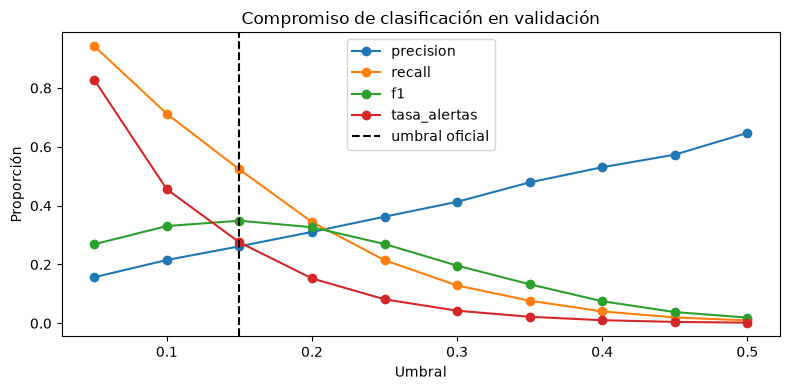

In [13]:
display(umbrales.round(4))
fig, ax = plt.subplots(figsize=(8,4))
for columna in ["precision", "recall", "f1", "tasa_alertas"]:
    ax.plot(umbrales["umbral"], umbrales[columna], marker="o", label=columna)
ax.axvline(resumen["umbral_elegido_en_validacion"], linestyle="--", color="black", label="umbral oficial")
ax.set(xlabel="Umbral", ylabel="Proporción", title="Compromiso de clasificación en validación")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Desempeño territorial — test

La evaluación por comuna revela **heterogeneidad de recall**. Entre las diez comunas con más operaciones, Santiago alcanza **42.0 %**, Las Condes **37.8 %**, Ñuñoa **21.1 %** y Quilicura **16.5 %**. La brecha Santiago–Quilicura es de **25.5 puntos porcentuales**.

Las diferencias indican que el modelo no identifica retrasos con igual sensibilidad en todos los destinos. **No constituyen por sí solas prueba de discriminación injustificada:** pueden intervenir tasas base distintas, composición de rutas, volumen de operaciones y otros factores.

Las comunas con pocos retrasos tienen estimaciones menos estables. Por eso se incorpora `muestra_suficiente_recall` como indicador descriptivo y se evita reajustar el umbral o los hiperparámetros usando resultados del test.


,comuna_destino,operaciones,retrasos,tasa_retrasos,tasa_alertas,precision,recall,muestra_suficiente_recall
0,Santiago,22358,4173,0.1866,0.2159,0.3632,0.4201,True
1,Las Condes,15973,2679,0.1677,0.1815,0.3498,0.3785,True
2,Maipú,14270,2005,0.1405,0.1093,0.3314,0.2579,True
3,Providencia,12868,1981,0.1539,0.1467,0.3506,0.3342,True
4,La Florida,12700,1736,0.1367,0.1111,0.3381,0.2748,True
5,Puente Alto,11299,1706,0.1510,0.1514,0.3413,0.3423,True
6,Ñuñoa,11088,1339,0.1208,0.0767,0.3325,0.2114,True
7,Valparaíso,7924,1208,0.1524,0.1417,0.3411,0.3171,True
8,Quilicura,7911,901,0.1139,0.0630,0.2992,0.1654,True
9,Viña del Mar,7908,1128,0.1426,0.1155,0.3582,0.2899,True


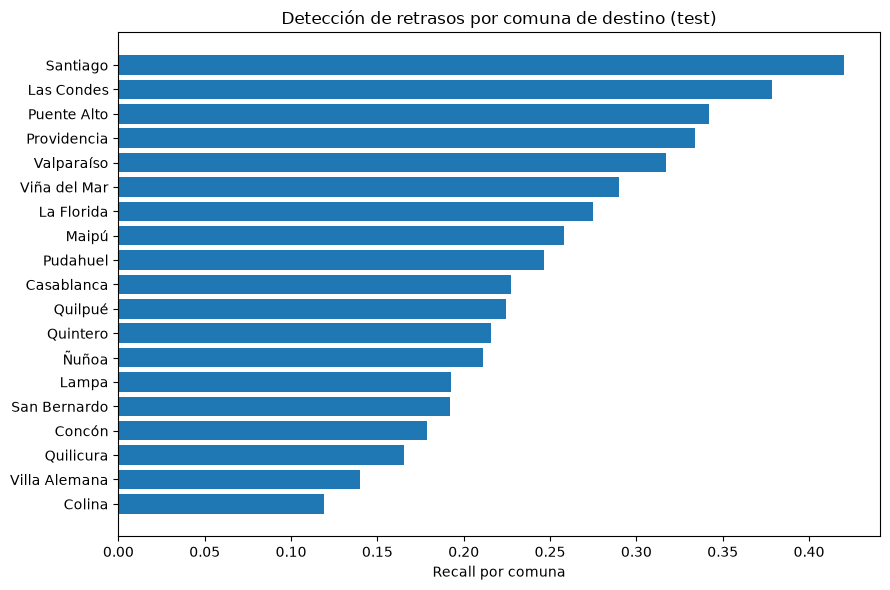

In [14]:
columnas = ["comuna_destino", "operaciones", "retrasos", "tasa_retrasos", "tasa_alertas", "precision", "recall", "muestra_suficiente_recall"]
display(comunas[columnas].round(4))
orden = comunas.sort_values("recall")
fig, ax = plt.subplots(figsize=(9,6))
ax.barh(orden["comuna_destino"], orden["recall"])
ax.set(xlabel="Recall por comuna", title="Detección de retrasos por comuna de destino (test)")
plt.tight_layout()
plt.show()

## 3. Síntesis de evaluación y limitaciones

1. **Selección reproducible:** se compararon dos algoritmos y se eligió XGBoost por desempeño de validación, sin consultar test.
2. **Compromiso operativo:** el umbral oficial 0.15 maximiza F1 en validación; bajar el umbral mejora recall a costa de más alertas.
3. **Errores de clasificación:** el test registra 15.049 retrasos no detectados y 12.776 falsas alarmas; ambos tipos de error deben considerarse en decisiones logísticas.
4. **Variación territorial:** existen diferencias de recall entre comunas, que merecen seguimiento y análisis contextual.
5. **Naturaleza sintética:** las distribuciones y relaciones fueron diseñadas en la simulación; la evaluación no sustituye una validación con datos reales.
6. **Separación temporal:** las métricas de test se registran como evaluación final; no deben emplearse para decidir nuevas variables, umbrales o hiperparámetros sin una nueva evaluación independiente.

**Relación con el objetivo de negocio:** una predicción de retraso no equivale a una reducción del retraso. Para demostrar una disminución del 20 % sería necesario definir intervenciones, costos y una evaluación del efecto de aplicarlas.


## 4. Explicabilidad global SHAP — evidencia H4-T2

Los valores SHAP se calcularon sobre una muestra reproducible de **500 operaciones de validación (julio de 2026)** y se agruparon por predictor original: las columnas de codificación one-hot y los indicadores de datos faltantes se suman por observación antes de calcular la importancia global.

La importancia global se presenta mediante la **media del valor absoluto SHAP** en el margen bruto del XGBoost (**log-odds**). Este valor indica cuánto influye una variable en la salida del modelo, **sin indicar por sí solo la dirección del efecto ni una variación en puntos porcentuales de probabilidad**.

Las mayores importancias obtenidas fueron:
- `es_hora_punta`: **0.4754**.
- `mes`: **0.3586**.
- `duracion_estimada_min`: **0.2315**.
- `comuna_destino`: **0.1710**.
- `experiencia_conductor_anios`: **0.1407**.

Esto muestra un predominio de variables temporales, de planificación y contexto territorial en las predicciones del modelo. No demuestra relaciones causales.

**Precaución sobre `mes`:** toda la muestra SHAP procede de **julio**, por lo que `mes = 7` en todas las observaciones. Su importancia y contribución reflejan cómo el modelo utiliza ese valor dentro de su representación aprendida; **esta visualización no permite concluir que el riesgo crezca progresivamente a medida que avanzan los meses**. Para estudiar variaciones entre meses se requeriría un análisis específico con registros de varios períodos, separado de la selección y evaluación final.


Muestra: 500 | Período: validacion (julio 2026)
Escala: log-odds / margen bruto de XGBoost; NO puntos porcentuales de probabilidad


,variable,valor
0,es_hora_punta,0.4754
1,mes,0.3586
2,duracion_estimada_min,0.2315
3,comuna_destino,0.1710
4,experiencia_conductor_anios,0.1407
5,distancia_km,0.1195
6,tipo_vehiculo,0.0979
7,dia_semana,0.0791
8,franja_horaria,0.0499
9,n_paquetes,0.0396


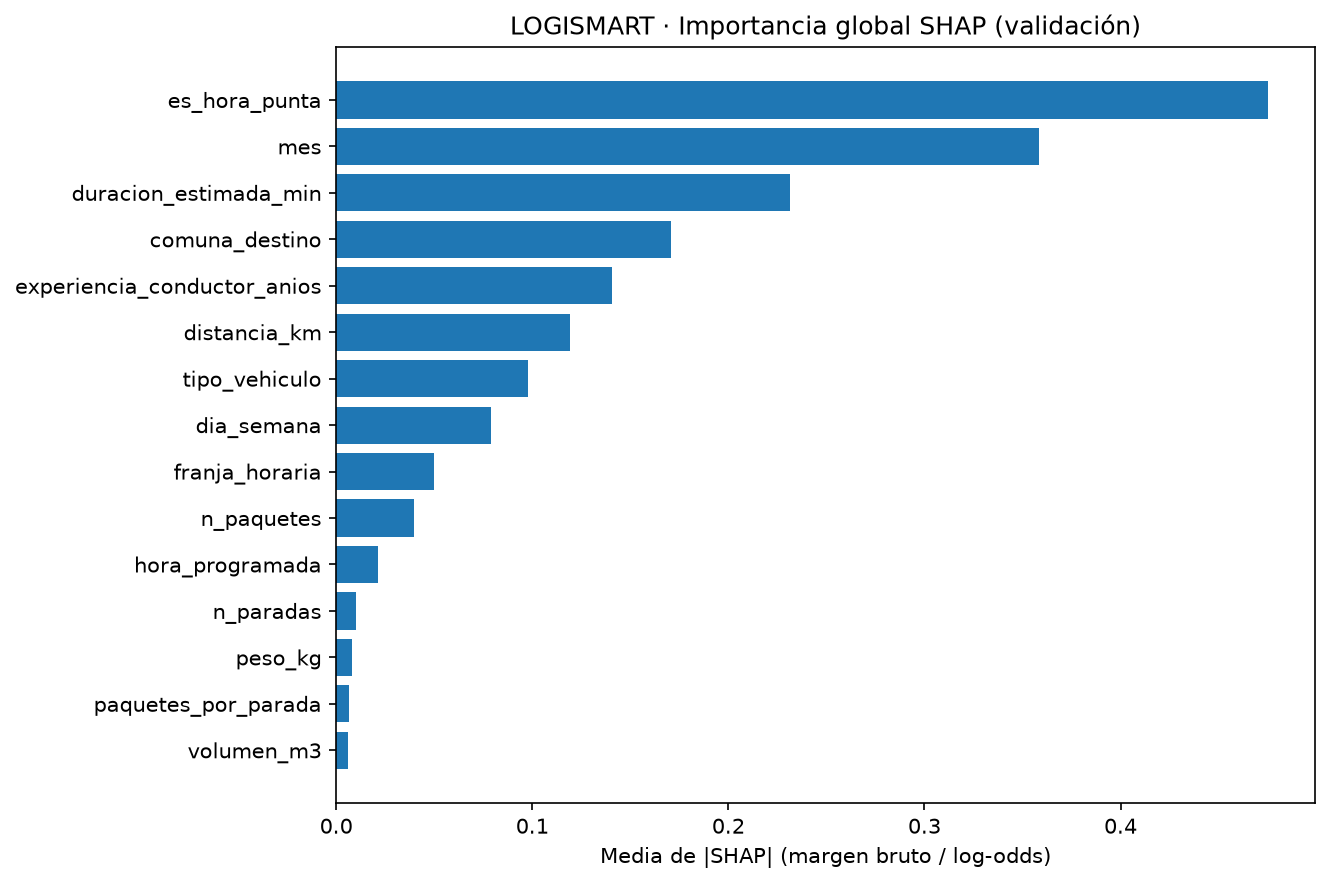

In [15]:
from IPython.display import Image, display
ruta_shap = resultados_dir / "explicabilidad_shap.json"
ruta_fig = graficos_dir / "importancia_shap.png"
if not ruta_shap.exists() or not ruta_fig.exists():
    raise FileNotFoundError("Ejecuta primero: python main.py --proceso explicar")
explicacion = json.loads(ruta_shap.read_text(encoding="utf-8"))
print("Muestra:", explicacion["numero_operaciones"], "| Período:", explicacion["conjunto_explicado"])
print("Escala:", explicacion["escala_shap"])
display(pd.DataFrame(explicacion["importancia_global_media_abs_shap"]).head(15).round(4))
display(Image(filename=str(ruta_fig)))

### Explicación local y lectura crítica

Una contribución SHAP positiva desplaza el **margen bruto** de XGBoost hacia un mayor riesgo y una negativa lo desplaza hacia un menor riesgo. Los valores están expresados en **log-odds**, no en porcentajes de probabilidad ni en efectos causales.

En la ejecución documentada, el ejemplo local elegido corresponde a la operación con **mayor probabilidad estimada dentro de la muestra de 500 registros**. Esa elección sirve para ilustrar cómo funciona el modelo, pero **no representa una operación promedio** ni una prueba de que sus características causen retrasos.


In [16]:
ejemplo = explicacion["ejemplo_local"]
print("Probabilidad predicha:", round(ejemplo["probabilidad_predicha"], 4))
display(pd.DataFrame(ejemplo["top_atribuciones_por_variable"]).head(12).round(4))

Probabilidad predicha: 0.6035


,variable,shap
0,duracion_estimada_min,0.6921
1,es_hora_punta,0.5780
2,distancia_km,0.3373
3,mes,0.3328
4,comuna_destino,0.2888
5,dia_semana,0.2618
6,experiencia_conductor_anios,0.2455
7,tipo_vehiculo,-0.0907
8,n_paquetes,0.0430
9,franja_horaria,0.0313


### Interpretación de la importancia SHAP global

`es_hora_punta` tiene la mayor influencia media; le siguen `mes` y `duracion_estimada_min`. También destacan `comuna_destino`, `experiencia_conductor_anios`, `distancia_km` y `tipo_vehiculo`. En cambio, `peso_kg`, `volumen_m3` y `paquetes_por_parada` presentan aportes mucho menores en esta ejecución.

Varias características están relacionadas entre sí: `es_hora_punta` se deriva de `hora_programada`, y la duración estimada se relaciona con distancia y número de paradas. Por tanto, la atribución de importancia puede concentrarse en algunas variables correlacionadas o derivadas. **No corresponde eliminar predictores únicamente por su menor importancia SHAP**.

El mes es particularmente sensible a la construcción del dataset sintético: el generador incorpora una evolución temporal del riesgo. Estas explicaciones deben interpretarse como un análisis del **comportamiento del modelo entrenado**, no como descubrimientos causales sobre transporte real.


## 5. SHAP beeswarm y waterfall — evidencia H4-T2

Los gráficos se generan en `src/explicabilidad.py` y se guardan en `output/graficos/`. El notebook únicamente los visualiza.

**Beeswarm:** cada punto es una operación de validación. El eje horizontal expresa la contribución SHAP al margen bruto del modelo. A la **derecha de cero** la variable aumenta el riesgo predicho y a la **izquierda** lo reduce. En variables numéricas, rojo representa valores relativamente altos y azul valores bajos; las variables categóricas se muestran en gris porque no existe una escala cuantitativa natural de color.

**Waterfall:** descompone la predicción de una operación individual. Parte del valor base **E[f(X)]**, suma las contribuciones positivas y negativas de las variables y llega a **f(x)**. Ambos extremos están en log-odds; para expresarlos como probabilidad hay que aplicar la función sigmoide.

**Interpretación de `mes`:** como las 500 operaciones proceden de julio, todos los puntos tienen el mismo mes. La dispersión de contribuciones SHAP para `mes` **no demuestra diferencias entre meses**, ni que un mes posterior aumente necesariamente los retrasos.


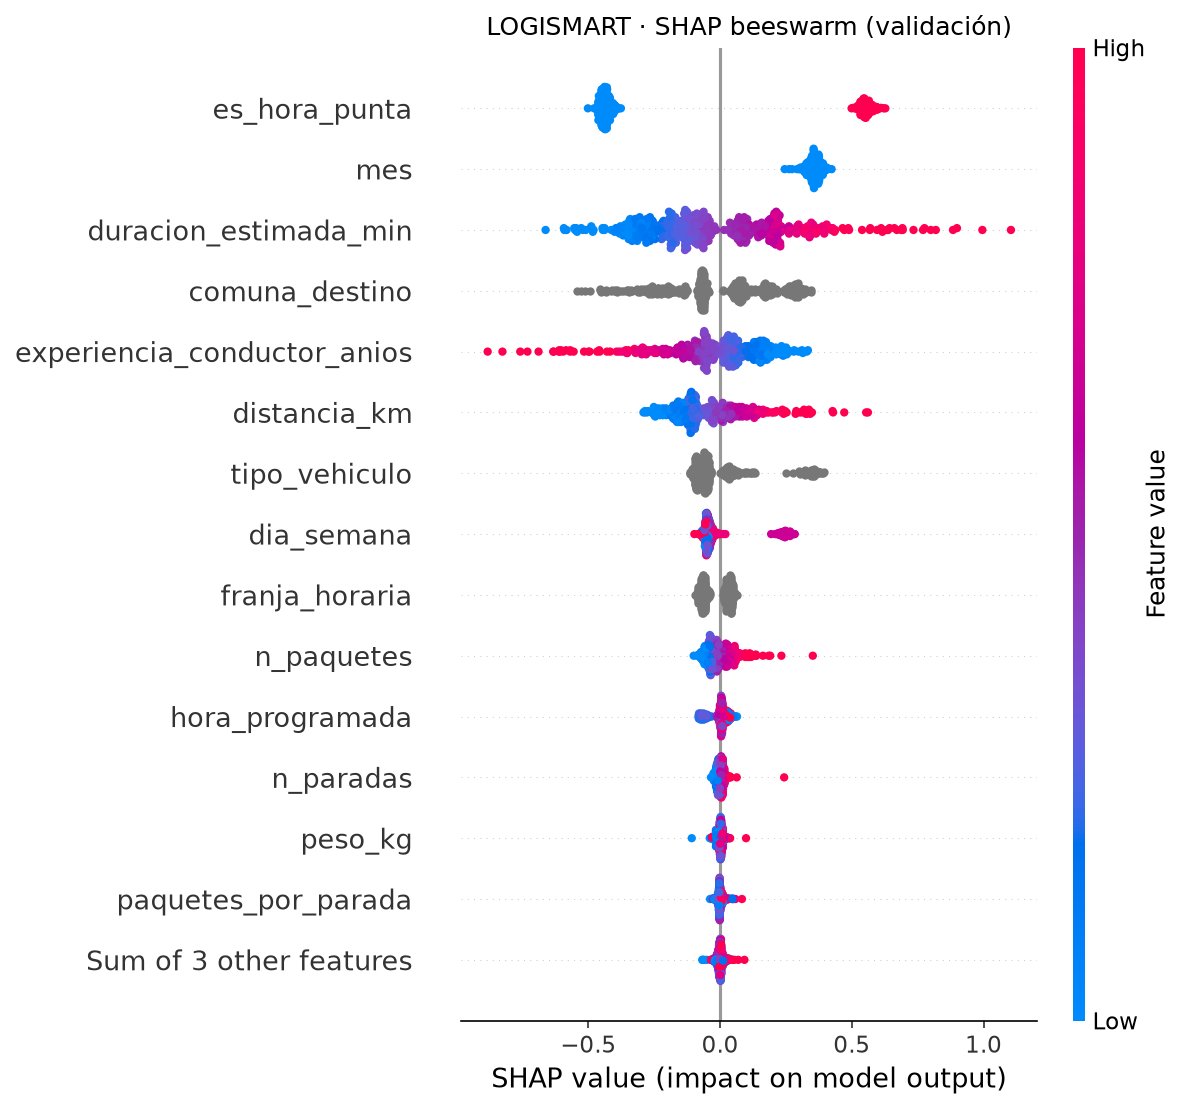

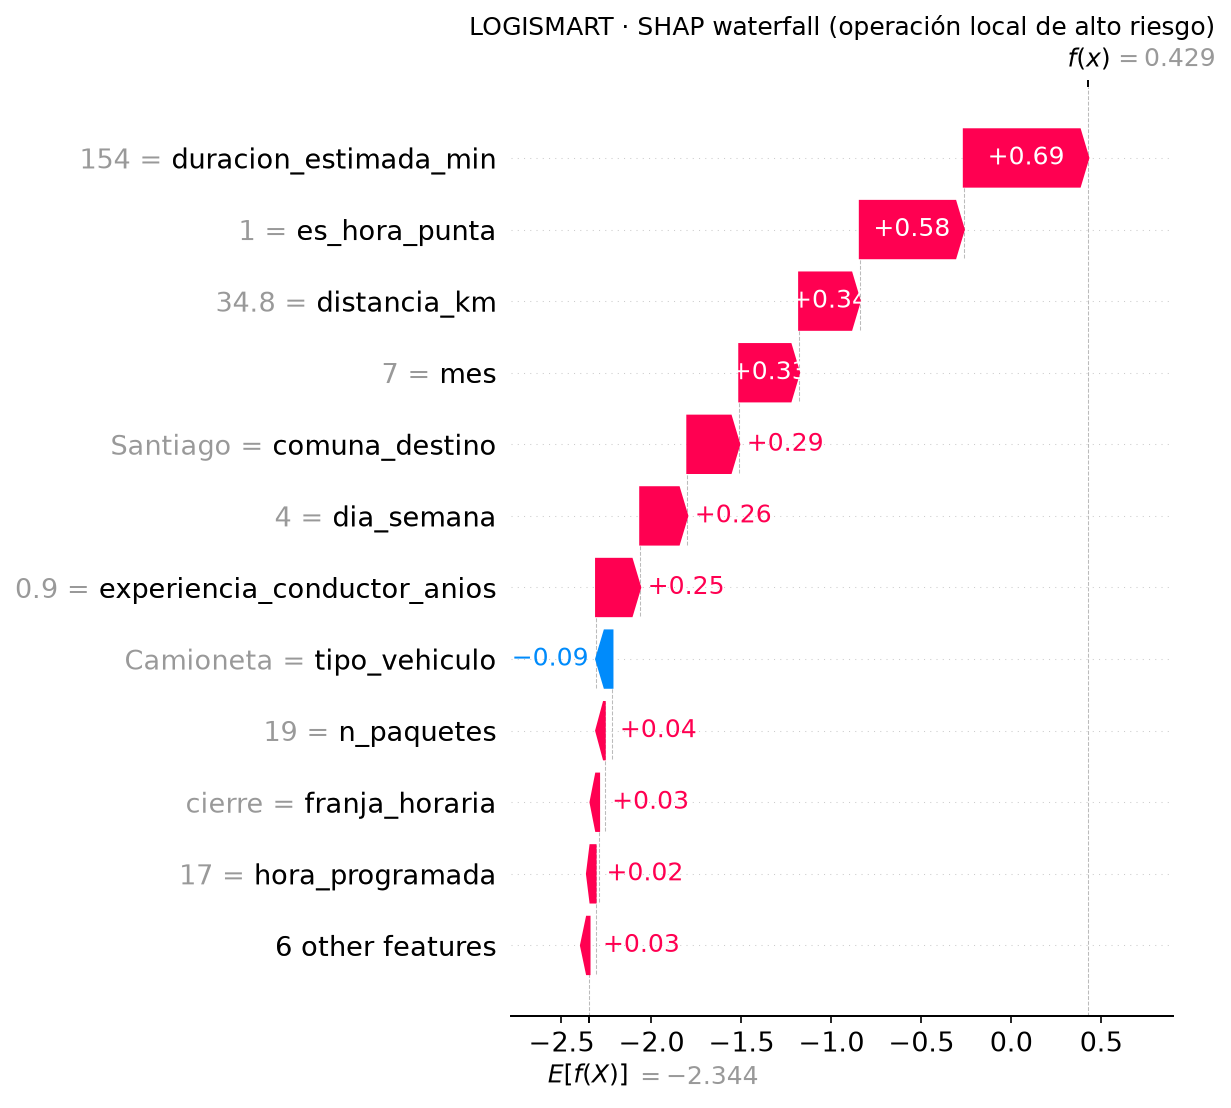

In [17]:
from IPython.display import Image, display

for nombre in ["beeswarm_shap.png", "waterfall_shap.png"]:
    ruta = graficos_dir / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"No existe {ruta}. Ejecuta python main.py --proceso explicar")
    display(Image(filename=str(ruta)))

### Interpretación del beeswarm

En la ejecución documentada se observan los siguientes patrones:
- **Hora punta:** `es_hora_punta = 1` aparece principalmente con contribuciones positivas; `0`, con negativas. El modelo asocia la condición de hora punta con una mayor predicción de riesgo.
- **Duración estimada y distancia:** los valores altos tienden a desplazarse hacia SHAP positivo y los bajos hacia SHAP negativo.
- **Experiencia del conductor:** una experiencia mayor tiende a mostrar contribuciones negativas; en la muestra, menor experiencia se asocia con un riesgo predicho mayor.
- **Comuna y tipo de vehículo:** sus puntos grises permiten apreciar diferencias en contribuciones, pero el color no indica un orden de categorías.
- **Mes:** toda la muestra pertenece a julio. Que SHAP sea positivo para `mes = 7` no prueba una tendencia creciente entre meses.

La interpretación describe asociaciones **aprendidas por XGBoost** dentro de un dataset simulado; no establece que intervenir sobre una variable produzca automáticamente el cambio predicho.

### Interpretación del waterfall: operación de alto riesgo

El ejemplo mostrado corresponde a una operación con **154 minutos** de duración estimada, **34.8 km** de recorrido, despacho programado a las **17:00**, destino **Santiago**, **19 paquetes** y **0.9 años** de experiencia del conductor.

El modelo parte de un margen base aproximado de **−2.344** y termina en **f(x) = 0.429**. Aplicando la sigmoide, este último valor equivale aproximadamente a **60.6 % de probabilidad predicha de retraso**: supera el umbral oficial de **15 %** y, por tanto, se clasifica como operación de riesgo.

Las mayores contribuciones positivas son **duración estimada (+0.69)**, **hora punta (+0.58)**, **distancia (+0.34)**, **mes (+0.33)** y **comuna destino (+0.29)**. La categoría **Camioneta** muestra una contribución negativa pequeña (aproximadamente **−0.09**). Estas contribuciones son cambios en el margen **log-odds**, no en puntos porcentuales.

**Límites de la interpretación local:** es un ejemplo intencionalmente seleccionado por alta probabilidad dentro de la muestra, no un caso representativo de todas las entregas. La descomposición explica cómo el modelo produjo su estimación y no constituye evidencia de que una modificación operativa específica evite el retraso.

### Cierre de H4-T2

El análisis reúne tres niveles complementarios: **importancia global** (magnitud media), **beeswarm** (dirección y dispersión) y **waterfall** (explicación individual). En conjunto, aporta trazabilidad a las decisiones del modelo, manteniendo las limitaciones propias de datos sintéticos y de la atribución predictiva.
